In [282]:
import math
import pandas as pd
import numpy as np
from pathlib import Path
from skimage.filters import gaussian
from cmcrameri import cm
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

### Some functions we need

In [283]:
def bin_dataframe_col(df, width):
    #Bins every columns of a dataframe by a given width
    #source: https://stackoverflow.com/questions/21921178/binning-a-numpy-array
    
    df_binned = pd.DataFrame()
    for col in df.columns:
        array = df[col].values
        bin_array = array[:(array.size // width) * width].reshape(-1, width).mean(axis=1)
        df_binned[col] = bin_array
    
    return df_binned

def combine_lineprofiles(directory, channel):
    #Combines all line profiles from a directory into a single dataframe
    df_concat_P = pd.DataFrame()
    df_concat_N = pd.DataFrame()

    for file in directory.glob('*.csv'):
        df_tidy = pd.read_csv(file, encoding='unicode_escape', engine='python')
        df_ratio = df_tidy.pivot(index='time (min)', columns='distance (um)', values=channel)

        if file.stem.endswith('P_lineProfile_tidy'):
            df_concat_P, df_ratio_cut_P = df_concat_P.align(df_ratio, join='outer', axis=1)
            df_concat_P = pd.concat([df_concat_P, df_ratio_cut_P])
        else:
            df_concat_N, df_ratio_cut_N = df_concat_N.align(df_ratio, join='outer', axis=1)
            df_concat_N = pd.concat([df_concat_N, df_ratio_cut_N])
    
    return df_concat_P.dropna(axis=1), df_concat_N.dropna(axis=1, thresh=len(df_concat_N)-2)


### Initial setup

You will have to specify the folder name for the folder where you stored your lineprofiles extracted from you're timelapse movies.  
In the case of this project the different conditions are as follows: 
- wt 
- galactose
- galactose_48h
- si_control
- TRAK1_kd
- TRAK1_oe
- TRAK2_kd
- TRAK2_oe

In [284]:
condition = 'TRAK1_oe'
time_interval = 3 #minutes
binning_width = 5 #set to 1 if no binning is desired

directory = Path(condition + '/all_lineprofiles')
tidy_directory = Path(condition + '/all_tidy')
kymo_directory = Path(condition + '/kymographs')

#colormap to use
custom_cmap = cm.roma_r(np.arange(256))
custom_cmap[255:, :] = np.array([0.8, 0.8, 0.8, 1])
cmap = mpl.colors.ListedColormap(custom_cmap, name='roma_r_gray', N=custom_cmap.shape[0])

### Convert the raw lineprofiles to tidy dataframes

In [285]:
for file in directory.glob('*Profile.csv'):
    #progress bar
    print(file.name)

    #Assign the green lineprofiles filename
    file_green = directory / file.name.replace('.csv', 'Green.csv')

    #Load the csv files for both the green and red channel. Drop the first column since it's useless
    df_green = pd.read_csv(file_green, encoding='unicode_escape', engine='python').drop(' ', axis=1)
    df_red = pd.read_csv(file, encoding='unicode_escape', engine='python').drop(' ', axis=1)
    #bin the values if desired
    if binning_width > 1:
        df_green = bin_dataframe_col(df_green, binning_width)
        df_red = bin_dataframe_col(df_red, binning_width)

    #Find the max value in the red channel at t0 and set it to be the conversion site (distance = 0)
    red_max = gaussian(df_red['t1'], sigma=2).argmax()
    #we want all conversion sites to be closer to the left in the final kymographs 
    #so I flip the values if this isn't already the case
    if len(df_red)/red_max < 2:
        df_green = df_green[::-1]
        df_green['distance (µm)'] = df_green['distance (µm)']*-1
        df_red = df_red[::-1]
        df_red['distance (µm)'] = df_red['distance (µm)']*-1

    conversion_site = df_red.loc[red_max, 'distance (µm)']
    df_red['distance (µm)'] = df_red['distance (µm)'] - conversion_site

    #Save the distance values as their own dataframe
    df_distance = df_red['distance (µm)'].round(3)

    #normalize all linegraphs for each timepoint
    df_green = (df_green-df_green.min())/(df_green.max()-df_green.min())
    df_red = (df_red-df_red.min())/(df_red.max()-df_red.min())

    #Initialise the final dataframe columns
    n_rows = df_green.shape[0]
    n_cols = df_green.shape[1]
    time_col = []
    size_col = []
    intensity_red_col = []
    intensity_green_col = []

    for i in range(n_cols - 1):
        time_col.extend([i*time_interval] * n_rows)
        size_col.extend(tuple(df_distance))
        intensity_green_col.extend(tuple(df_green['t' + str(i+1)]))
        intensity_red_col.extend(tuple(df_red['t' + str(i+1)]))
    
    df = pd.DataFrame(
        {'time (min)' : time_col,
         'distance (um)' : size_col,
         'average green intensity' : intensity_green_col,
         'average red intensity' : intensity_red_col},
    )
    df['ratio (red/green)'] = df['average red intensity'] / df['average green intensity']

    df.to_csv(tidy_directory / file.name.replace('.csv', '_tidy.csv'))

230720_S3_TRAK1_oe1_s13_N_lineProfile.csv
230720_S3_TRAK1_oe1_s15_N_lineProfile.csv
230720_S3_TRAK1_oe1_s2_N_lineProfile.csv
230720_S3_TRAK1_oe1_s4_N_lineProfile.csv
230720_S3_TRAK1_oe1_s5_N_lineProfile.csv
230720_S3_TRAK1_oe1_s9_N_lineProfile.csv
230720_S3_TRAK1_oe2_s12_N_lineProfile.csv
230720_S3_TRAK1_oe2_s16_N_lineProfile.csv
230720_S3_TRAK1_oe2_s17_N_lineProfile.csv
230720_S3_TRAK1_oe2_s18_N_lineProfile.csv
230720_S3_TRAK1_oe2_s19_P_lineProfile.csv
230720_S3_TRAK1_oe2_s2_N_lineProfile.csv
230720_S3_TRAK1_oe2_s7_N_lineProfile.csv
230720_S3_TRAK1_oe2_s8_N_lineProfile.csv
230720_S3_TRAK1_oe2_s9_N_lineProfile.csv
240111_S3_TRAK1_oe1_s1_N_lineProfile.csv
240111_S3_TRAK1_oe1_s2_N_lineProfile.csv
240111_S3_TRAK1_oe1_s3_N_lineProfile.csv
240111_S3_TRAK1_oe1_s7_N_lineProfile.csv
240125_S3_TRAK1_oe1_s2_N_lineProfile.csv


### Combine all lineprofiles

In [286]:
df_concat_P_ratio, df_concat_N_ratio = combine_lineprofiles(tidy_directory, 'ratio (red/green)')
df_concat_P_green, df_concat_N_green = combine_lineprofiles(tidy_directory, 'average green intensity')
df_concat_P_red, df_concat_N_red = combine_lineprofiles(tidy_directory, 'average red intensity')

Save the combined sets of lineprofiles

In [287]:
df_concat_N_ratio.to_csv(kymo_directory / ('all_N_ratio_red_green.csv'))
df_concat_P_ratio.to_csv(kymo_directory / ('all_P_ratio_red_green.csv'))

df_concat_N_red.to_csv(kymo_directory / ('all_N_average_red_intensity.csv'))
df_concat_P_red.to_csv(kymo_directory / ('all_P_average_red_intensity.csv'))

df_concat_N_green.to_csv(kymo_directory / ('all_N_average_green_intensity.csv'))
df_concat_P_green.to_csv(kymo_directory / ('all_P_average_green_intensity.csv'))

An example of what a combined set of lineprofiles looks like for the perinuclear case

<Axes: xlabel='distance (um)'>

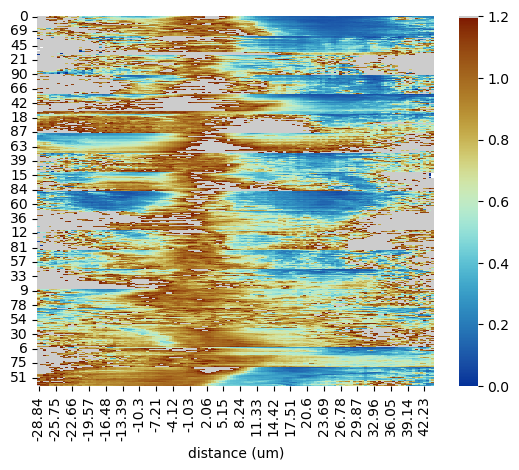

In [288]:
sns.heatmap(df_concat_N_ratio, robust=True, cmap=cmap, vmin=0, vmax=1.2)

### Save the median, mean and std kymographs

In [290]:
df_concat_N_red.groupby(level=0).mean().to_csv(kymo_directory / ('red_N.csv'))
df_concat_P_red.groupby(level=0).mean().to_csv(kymo_directory / ('red_P.csv'))
df_concat_N_green.groupby(level=0).mean().to_csv(kymo_directory / ('green_N.csv'))
df_concat_P_green.groupby(level=0).mean().to_csv(kymo_directory / ('green_P.csv'))
df_concat_N_ratio.groupby(level=0).mean().to_csv(kymo_directory / ('mean_of_ratios_N.csv'))
df_concat_P_ratio.groupby(level=0).mean().to_csv(kymo_directory / ('mean_of_ratios_P.csv'))
df_concat_N_ratio.groupby(level=0).median().to_csv(kymo_directory / ('median_of_ratios_N.csv'))
df_concat_P_ratio.groupby(level=0).median().to_csv(kymo_directory / ('median_of_ratios_P.csv'))
df_concat_N_red.groupby(level=0).std().to_csv(kymo_directory / ('std_red_N.csv'))
df_concat_P_red.groupby(level=0).std().to_csv(kymo_directory / ('std_red_P.csv'))
df_concat_N_green.groupby(level=0).std().to_csv(kymo_directory / ('std_green_N.csv'))
df_concat_P_green.groupby(level=0).std().to_csv(kymo_directory / ('std_green_P.csv'))
df_concat_N_ratio.groupby(level=0).std().to_csv(kymo_directory / ('std_of_ratios_N.csv'))
df_concat_P_ratio.groupby(level=0).std().to_csv(kymo_directory / ('std_of_ratios_P.csv'))

In [291]:
df_mean_N = df_concat_N_ratio.groupby(level=0).median()
df_mean_P = df_concat_P_ratio.groupby(level=0).median()

### And here is what the kymographs look like

<Axes: xlabel='distance (um)'>

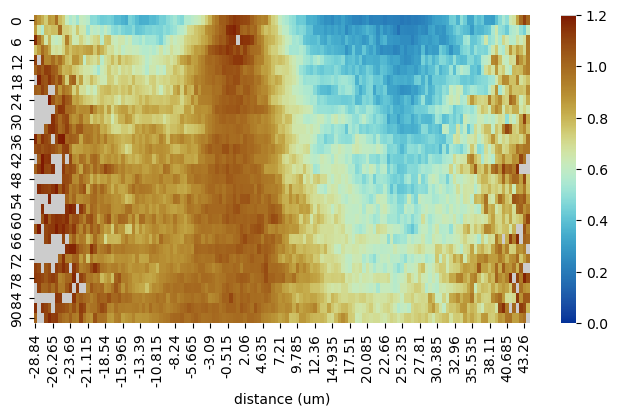

In [292]:
plt.figure(figsize=(8,4))
sns.heatmap(df_mean_N, robust=True, cmap=cmap, vmin=0, vmax=1.2)

<Axes: xlabel='distance (um)'>

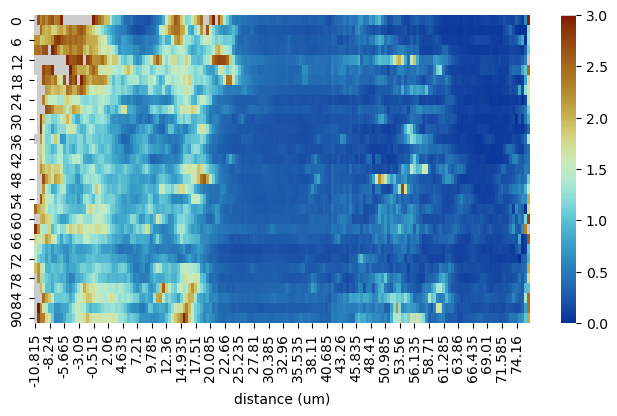

In [293]:
plt.figure(figsize=(8,4))
sns.heatmap(df_mean_P, robust=True, cmap=cmap, vmin=0, vmax=3.0)